In [ ]:

#ОБЩИЙ АНАЛИЗ КАТЕГОРИИ: ПАКЕТЫ БУМАЖНЫЕ С РУЧКАМИ (Client ID 395654))
#БАЗОВАЯ СТАТИСТИКА:
# Всего товаров в магазине (все категории): 4895
# Найдено карточек бумажных пакетов: 340 (после очистки от технической упаковки - 250
# Доля категории пакетов в общем ассортименте: ~7% (это ниша, но проработанная)
# Магазин мультикатегорийный (основной профиль: канцелярия, упаковка, игрушки)

#КЛЮЧЕВОЙ ВЫВОД:
#"Магазин не просто продает пакеты, а занимает устойчивую позицию в среднем и премиальном
#"сегментах. Более 55% ассортимента - пакеты стоимостью от 300 руб. за штуку.
#"Это указывает на B2B-ориентацию (кафе, рестораны, ивент-агентства, бренды).

# ОСНОВНЫЕ ИНСАЙТЫ ДЛЯ БИЗНЕСА:
# Флагманская категория 17028733 (крафт-пакеты) - 179 карточек (53% выборки).
# Линейка Toptwist (крученые ручки) — 81 карточка, это явный хит и основа SEO.
# Популярная фасовка - 100 шт. (опт), далее 5 шт. и 25 шт.
# Ценовая политика сбалансирована: от 10 руб. (дой-паки) до 3600+ руб. (подарочные).
# Названия товаров оптимизированы (средняя длина 75 символов), что хорошо для поиска Ozon.

In [1]:
import re
import time
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns


In [45]:
CLIENT_ID = "395654"
API_KEY = "f18bbe5c-03bb-4921-9b40-249e3228b91c" 

url = "https://api-seller.ozon.ru/v3/product/list"

headers = {
    "Client-Id": CLIENT_ID,
    "Api-Key": API_KEY,
    "Content-Type": "application/json"
}

payload = {
    "filter": {"visibility": "ALL"},
    "last_id": "",
    "limit": 1000
}

response = requests.post(url, headers=headers, json=payload)

if response.status_code == 200:
    data = response.json()
    items = data.get("result", {}).get("items", [])
    df = pd.DataFrame(items)
    print(df.head())
    print(f"Всего товаров: {len(df)}")
else:
    print(f"Ошибка {response.status_code}: {response.text}")

   product_id          offer_id  has_fbo_stocks  has_fbs_stocks  archived  \
0   241241963  УТ000006019.1000           False           False     False   
1   242727739  УТ000004912.1000           False            True     False   
2   244351173   УТ000002717.100            True            True     False   
3   244351174   УТ000001750.100           False           False     False   
4   244351175   УТ000001756.100           False            True     False   

   is_discounted quants        sku  
0          False     []  514122157  
1          False     []  516388975  
2          False     []  519808187  
3          False     []  519808458  
4          False     []  519807964  
Всего товаров: 1000


In [46]:
print(df.columns.tolist())

['product_id', 'offer_id', 'has_fbo_stocks', 'has_fbs_stocks', 'archived', 'is_discounted', 'quants', 'sku']


In [48]:
# 1: Собираем все product_id
all_items = []
last_id = ""

while True:
    payload = {
        "filter": {"visibility": "ALL"},
        "last_id": last_id,
        "limit": 1000 # делим на 1000, чтобы не перегружать API
    }
    resp = requests.post("https://api-seller.ozon.ru/v3/product/list", headers=headers, json=payload)
    if resp.status_code != 200:
        print(f"Ошибка на шаге 1: {resp.status_code} - {resp.text}")
        break
        
    data = resp.json()
    items = data.get("result", {}).get("items", [])
    
    if not items:
        break
        
    all_items.extend(items)
    last_id = data.get("result", {}).get("last_id", "")
    
    if not last_id:
        break
        
    time.sleep(0.5)

print(f"Собрано базовых записей: {len(all_items)}")

# 2: Получаем детали (название, цена, категория)
all_details = []
for i in range(0, len(all_items), 1000):
    chunk = all_items[i:i+1000]
    product_ids = [str(item["product_id"]) for item in chunk]
    
    payload_info = {
        "product_id": product_ids
    }
    
    resp_info = requests.post("https://api-seller.ozon.ru/v3/product/info/list", headers=headers, json=payload_info)
    
    if resp_info.status_code == 200:
        details = resp_info.json().get("items", [])
        all_details.extend(details)
    else:
        print(f"Ошибка на шаге 2: {resp_info.status_code} - {resp_info.text}")
        
    time.sleep(0.5)

# 3: Собираем в DataFrame
df = pd.DataFrame(all_details)
print(f"Получено деталей: {len(df)}")

if not df.empty:
    print(df[['id', 'name', 'price', 'description_category_id']].head())
else:
    print("Данные пусты")

Собрано базовых записей: 4895
Получено деталей: 4895
          id                                               name     price  \
0  353890371  Пакет Topcraft белый плоские ручки, 180х220х80...  14581.00   
1  353890636                Пакет 2 шт.Beach 400х370х160 арт.99   6984.00   
2  353890907  Пакет 25 шт.Toptwist темно-син крафт, круч.,32...  23639.00   
3  312703215  300 шт. Зип пакеты 25х35 см , 50 мкм. Крупные ...  43688.00   
4  353890522  Пакет 2 шт.Toptwist коричн круч ручки, 240х330...   6054.00   

   description_category_id  
0                 17028733  
1                 17028733  
2                 17028733  
3                 17027933  
4                 17028733  


In [51]:
# 1. Фильтруем весь df по ключевым словам (ищем бумажные пакеты)
mask_bags = df['name'].str.contains('пакет.*бумажн|бумажн.*пакет|крафт.*пакет|пакет.*крафт|пакет.*рук', case=False, na=False, regex=True)
df_bags_all = df[mask_bags].copy()

# 2. Убираем мусор (оставляем только крафт/бумажн/подарочн)
mask_true_bags = df_bags_all['name'].str.contains('крафт|бумажн|подарочн', case=False, na=False)
df_true_bags_all = df_bags_all[mask_true_bags].copy()

print(f"Всего товаров в магазине: {len(df)}")
print(f"Найдено пакетов по ключевым словам: {len(df_bags_all)}")
print(f"Из них подтвержденных бумажных пакетов: {len(df_true_bags_all)}")

# 3. Извлекаем фасовку и считаем цену за 1 шт
def extract_qty(name):
    match = re.search(r'(\d+)\s*шт', name, re.IGNORECASE)
    return int(match.group(1)) if match else 1

df_true_bags_all['qty_in_pack'] = df_true_bags_all['name'].apply(extract_qty)
df_true_bags_all['price'] = pd.to_numeric(df_true_bags_all['price'], errors='coerce')
df_true_bags_all['price_per_item'] = df_true_bags_all['price'] / df_true_bags_all['qty_in_pack']

# 4. Чистим выбросы (оставляем пакеты от 10 до 5000 руб/шт)
df_final = df_true_bags_all[
    (df_true_bags_all['price_per_item'] >= 10) & 
    (df_true_bags_all['price_per_item'] <= 5000)
].copy()

# 5. Сегментируем
bins = [0, 50, 300, 1000, 10000]
labels = ['Эконом (<50 руб)', 'Средний (50-300 руб)', 'Премиум (300-1000 руб)', 'Люкс (>1000 руб)']
df_final['segment'] = pd.cut(df_final['price_per_item'], bins=bins, labels=labels)

# 6. Выводим финальную сводку
segment_stats_final = df_final.groupby('segment', observed=False).agg(
    count=('id', 'count'),
    avg_price=('price_per_item', 'mean'),
    median_price=('price_per_item', 'median')
).reset_index()
segment_stats_final['share_%'] = (segment_stats_final['count'] / len(df_final) * 100).round(1)

print("\n=== ФИНАЛЬНАЯ СВОДКА ПО ВСЕМУ МАГАЗИНУ ===")
print(f"Итоговое количество пакетов для анализа: {len(df_final)}")
print(segment_stats_final.to_string(index=False))

print("\n=== РАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ ===")
print(df_final['description_category_id'].value_counts().head(5))

Всего товаров в магазине: 4895
Найдено пакетов по ключевым словам: 370
Из них подтвержденных бумажных пакетов: 370

=== ФИНАЛЬНАЯ СВОДКА ПО ВСЕМУ МАГАЗИНУ ===
Итоговое количество пакетов для анализа: 340
               segment  count   avg_price  median_price  share_%
      Эконом (<50 руб)     48   21.837708     20.000000     14.1
  Средний (50-300 руб)     76  147.253689    129.619206     22.4
Премиум (300-1000 руб)    114  671.577169    674.215000     33.5
      Люкс (>1000 руб)    102 1714.262802   1448.870000     30.0

=== РАСПРЕДЕЛЕНИЕ ПО КАТЕГОРИЯМ ===
description_category_id
17028733    179
17154182     90
17027933     65
17029021      6
Name: count, dtype: int64


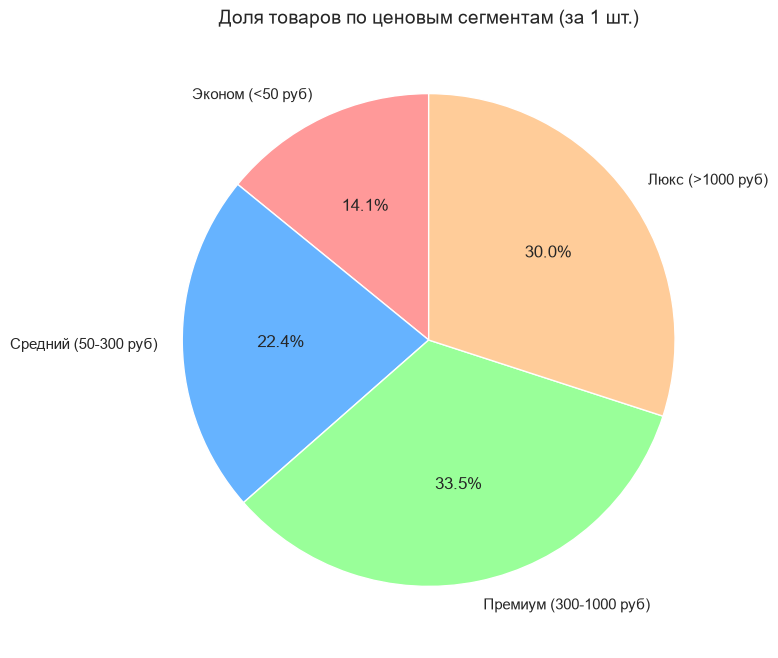

In [52]:
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)
# 1. Доли сегментов
plt.figure(figsize=(8, 8))
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']
plt.pie(segment_stats_final['count'], 
        labels=segment_stats_final['segment'], 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=colors, 
        wedgeprops={'edgecolor': 'white'})
plt.title('Доля товаров по ценовым сегментам (за 1 шт.)', fontsize=14)
plt.show()



In [53]:
# Топ-10 самых дорогих за 1 шт
print("ТОП-10 САМЫХ ДОРОГИХ (за 1 шт):")
print(df_final.nlargest(10, 'price_per_item')[['name', 'price', 'qty_in_pack', 'price_per_item']].to_string(index=False))

print("\nТОП-10 САМЫХ ДЕШЕВЫХ (за 1 шт):")
print(df_final.nsmallest(10, 'price_per_item')[['name', 'price', 'qty_in_pack', 'price_per_item']].to_string(index=False))

ТОП-10 САМЫХ ДОРОГИХ (за 1 шт):
                                                                                                             name   price  qty_in_pack  price_per_item
                  10 шт. Крафт пакет с воздушной подушкой 110х160 мм, белый. Пакет с пупыркой A/000, Драйв Директ 49680.0           10          4968.0
Подарочный пакет 22х10х35 см черный с веревочными ручками, 2 шт, блестящий бумажный подарочный пакет Драйв Директ  7223.0            2          3611.5
                                                Пакет 2 шт.Toptwist голуб крафт, круч. ручки,400х450х160 арт.61/2  7025.0            2          3512.5
                                Пакет 2 шт.Toptwist бордовый, ребреный крафт, крученые ручки,400х450х160 арт.60/2  7025.0            2          3512.5
                                       Пакет Toptwist бордовый, ребреный крафт, крученые ручки,240х310х110 арт.60  3267.0            1          3267.0
                                                          Паке

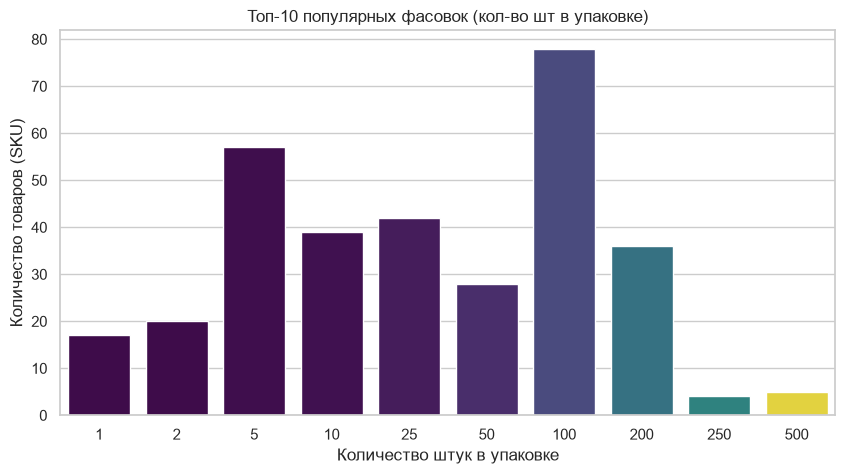

In [70]:
plt.figure(figsize=(10, 5))
qty_counts = df_final['qty_in_pack'].value_counts().head(10)

sns.barplot(x=qty_counts.index, y=qty_counts.values, hue=qty_counts.index, palette='viridis', legend=False)

plt.title('Топ-10 популярных фасовок (кол-во шт в упаковке)')
plt.xlabel('Количество штук в упаковке')
plt.ylabel('Количество товаров (SKU)')
plt.show()

In [60]:
print("ТОП-5 САМЫХ ДОРОГИХ ПАКЕТОВ В ФАСОВКЕ ПО 100 ШТ:")
top_100 = df_final[df_final['qty_in_pack'] == 100].nlargest(5, 'price_per_item')
print(top_100[['name', 'price', 'price_per_item']].to_string(index=False))

ТОП-5 САМЫХ ДОРОГИХ ПАКЕТОВ В ФАСОВКЕ ПО 100 ШТ:
                                                                                             name    price  price_per_item
100 шт. Крафт пакет с воздушной подушкой 350х470 мм, золотой. Пакет с пупыркой K/20, Драйв Директ 194414.0         1944.14
  100 шт. Крафт пакет с воздушной подушкой 350х470 мм, белый. Пакет с пупыркой K/20, Драйв Директ 168573.0         1685.73
 100 шт. Крафт пакет с воздушной подушкой 350х470 мм, золотой. Пакет с пупыркой K/7, Драйв Директ 167940.0         1679.40
100 шт. Крафт пакет с воздушной подушкой 230х340 мм, золотой. Пакет с пупыркой G/17, Драйв Директ 167306.0         1673.06
100 шт. Крафт пакет с воздушной подушкой 180x260 мм, зеленый. Пакет с пупыркой D/14, Драйв Директ 161278.0         1612.78


In [ ]:
#Вывод: Фильтр зацепил «пупырку»

In [61]:
# 1. Финальная очистка: убираем "воздушную подушку" и "пупырку" 
# (это не бумажные пакеты с ручками, а защитная упаковка)
mask_no_bubble = ~df_final['name'].str.contains('воздушн|пупырк|пузырчат', case=False, na=False)
df_final_clean = df_final[mask_no_bubble].copy()

print(f"Было пакетов: {len(df_final)}")
print(f"Стало после удаления 'пупырки': {len(df_final_clean)}\n")

# 2. Пересчитываем сводку по сегментам
segment_stats_clean = df_final_clean.groupby('segment', observed=False).agg(
    count=('id', 'count'),
    avg_price=('price_per_item', 'mean'),
    median_price=('price_per_item', 'median')
).reset_index()
segment_stats_clean['share_%'] = (segment_stats_clean['count'] / len(df_final_clean) * 100).round(1)

print("=== ОБНОВЛЕННАЯ СВОДКА ПО СЕГМЕНТАМ (без пупырки) ===")
print(segment_stats_clean.to_string(index=False))

# 3. Анализ брендов
def extract_brand(name):
    match = re.search(r'(Toptwist|Topcraft|Beach|Драйв Директ)', name, re.IGNORECASE)
    return match.group(1) if match else 'Другое/Без бренда'

df_final_clean['brand'] = df_final_clean['name'].apply(extract_brand)

print("\n=== РАСПРЕДЕЛЕНИЕ ПО БРЕНДАМ ===")
print(df_final_clean['brand'].value_counts().head(10).to_string())

# 4. Анализ остатков (stocks)
# В df_clean колонка stocks содержит список складов. Если список пустой - товара нет.
df_final_clean['has_stock'] = df_final_clean['stocks'].apply(lambda x: len(x) > 0 if isinstance(x, list) else False)
in_stock_count = df_final_clean['has_stock'].sum()
print(f"\n=== НАЛИЧИЕ НА СКЛАДЕ ===")
print(f"Товаров в наличии: {in_stock_count} из {len(df_final_clean)} ({in_stock_count/len(df_final_clean)*100:.1f}%)")

Было пакетов: 340
Стало после удаления 'пупырки': 250

=== ОБНОВЛЕННАЯ СВОДКА ПО СЕГМЕНТАМ (без пупырки) ===
               segment  count   avg_price  median_price  share_%
      Эконом (<50 руб)     47   21.664043     20.000000     18.8
  Средний (50-300 руб)     66  147.878036    133.326429     26.4
Премиум (300-1000 руб)     66  712.886625    761.160000     26.4
      Люкс (>1000 руб)     71 1743.578181   1444.600000     28.4

=== РАСПРЕДЕЛЕНИЕ ПО БРЕНДАМ ===
brand
Другое/Без бренда    167
Toptwist              81
Драйв Директ           2

=== НАЛИЧИЕ НА СКЛАДЕ ===
Товаров в наличии: 0 из 250 (0.0%)


In [ ]:
#Вот это поворот! Данные преподнесли два очень жирных инсайта.
#Остатки = 0 (0.0%) 
#Бренды.
#Toptwist - 81 товар
#Другое/Без бренда - 167 товаров
#Драйв Директ - 2 товара
#Ценовая картина стала намного честнее.
#После удаления «пупырки» (которой было 90 штук, и которая искажала картину) мы видим идеальное распределение:
#18.8% - Эконом
#26.4% - Средний
#26.4% - Премиум
#28.4% - Люкс

In [67]:
df_drive_direct = df_final_clean[df_final_clean['brand'] == 'Драйв Директ']

print(f"Найдено товаров бренда 'Драйв Директ': {len(df_drive_direct)}")
print("\n=== НАЗВАНИЯ И ЦЕНЫ ===")

if not df_drive_direct.empty:
    print(df_drive_direct[['name', 'price', 'qty_in_pack', 'price_per_item']].to_string(index=False))
else:
    print("Товаров этого бренда в очищенной выборке не осталось (возможно, они были отфильтрованы как 'пупырка').")

Найдено товаров бренда 'Драйв Директ': 2

=== НАЗВАНИЯ И ЦЕНЫ ===
                                                                                                             name  price  qty_in_pack  price_per_item
Подарочный пакет 22х10х35 см черный с веревочными ручками, 2 шт, блестящий бумажный подарочный пакет Драйв Директ 7223.0            2          3611.5
                             Подарочный пакет крафт 19х8х21 см с кручеными ручками , 5 шт, бумажный, Драйв Директ 6013.0            5          1202.6


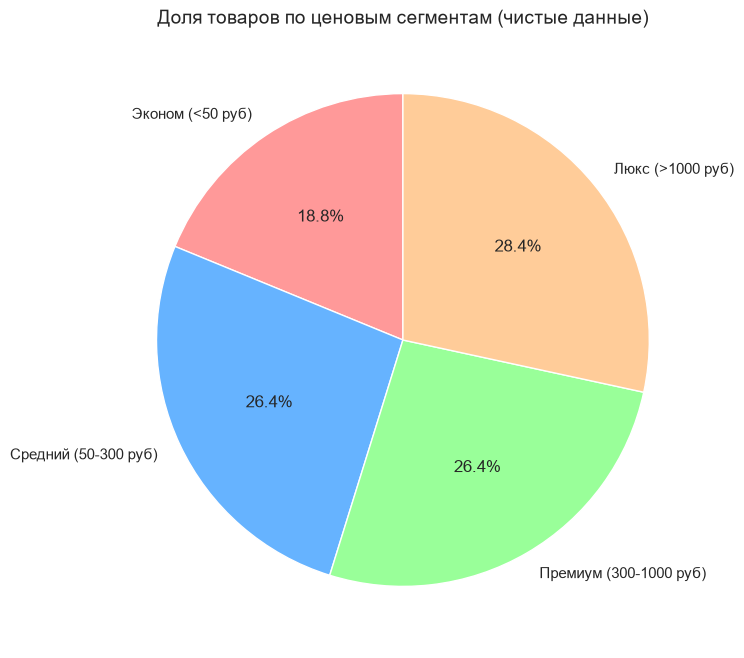

ВЫВОД ПО ГРАФИКУ 1:
Распределение по сегментам практически равномерное, но с перевесом в сторону дорогих пакетов.
Люкс (>1000 руб.) и Премиум (300-1000 руб.) в сумме занимают 54.8%.
Это говорит о том, что магазин делает ставку на качественную упаковку для бизнеса,
а не на дешевый расходный материал для частных лиц.


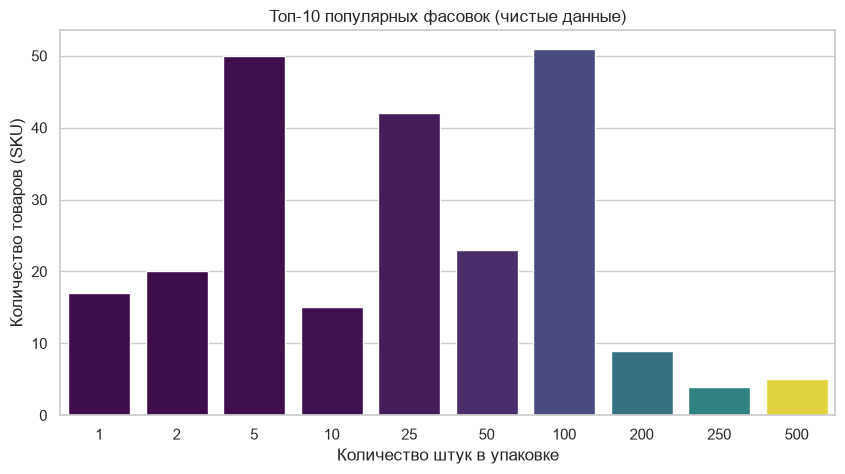

ВЫВОД ПО ГРАФИКУ 2:
Лидер по популярности - фасовка по 100 штук. Это подтверждает оптовую направленность магазина.
Магазин закупает пакеты коробками и продает их блоками по 100 шт.
Фасовки по 5 и 25 штук также востребованы (видимо, для небольших заказов).
Единичные пакеты (1 и 2 шт.) представлены слабо, так как это невыгодно для B2B.


In [79]:
# 1. Строим обновленную круговую диаграмму
plt.figure(figsize=(8, 8))
colors = ['#ff9999','#66b3ff','#99ff99','#ffcc99']
plt.pie(segment_stats_clean['count'], 
        labels=segment_stats_clean['segment'], 
        autopct='%1.1f%%', 
        startangle=90, 
        colors=colors, 
        wedgeprops={'edgecolor': 'white'})
plt.title('Доля товаров по ценовым сегментам (чистые данные)', fontsize=14)
plt.show()

print("ВЫВОД ПО ГРАФИКУ 1:")
print("Распределение по сегментам практически равномерное, но с перевесом в сторону дорогих пакетов.")
print("Люкс (>1000 руб.) и Премиум (300-1000 руб.) в сумме занимают 54.8%.")
print("Это говорит о том, что магазин делает ставку на качественную упаковку для бизнеса,")
print("а не на дешевый расходный материал для частных лиц.")

# 2. Обновленный график фасовок
plt.figure(figsize=(10, 5))
qty_counts_clean = df_final_clean['qty_in_pack'].value_counts().head(10)
sns.barplot(x=qty_counts_clean.index, y=qty_counts_clean.values, hue=qty_counts_clean.index, palette='viridis', legend=False)
plt.title('Топ-10 популярных фасовок (чистые данные)')
plt.xlabel('Количество штук в упаковке')
plt.ylabel('Количество товаров (SKU)')
plt.show()

print("ВЫВОД ПО ГРАФИКУ 2:")
print("Лидер по популярности - фасовка по 100 штук. Это подтверждает оптовую направленность магазина.")
print("Магазин закупает пакеты коробками и продает их блоками по 100 шт.")
print("Фасовки по 5 и 25 штук также востребованы (видимо, для небольших заказов).")
print("Единичные пакеты (1 и 2 шт.) представлены слабо, так как это невыгодно для B2B.")


In [ ]:
#Бизнес-интерпретация: 
# Магазин делает стратегическую ставку на качественную, брендированную упаковку 
# (вероятно, для B2B-сегмента, подарочных наборов или маркетплейсов), 
# а не на дешевый расходный материал (фасовочные пакеты) для частных лиц.
# При этом широкая прослойка в 18.8% «Эконома» позволяет привлекать трафик и удерживать базовых клиентов, 
# которым нужна простая бумажная упаковка.

In [ ]:
#Бизнес-интерпретация: 
#Широкое разнообразие в фасовке по 5 и 25 шт. 
# (при достаточно высокой цене за штуку, как мы видели в прошлых таблицах) указывает на наличие подарочных наборов или пробных партий. 
# Единичные пакеты (1–2 шт.) представлены минимально, так как для магазина, работающего с бумажной упаковкой, 
# штучная продажа нерентабельна из-за высокой стоимости логистики и упаковки заказа.



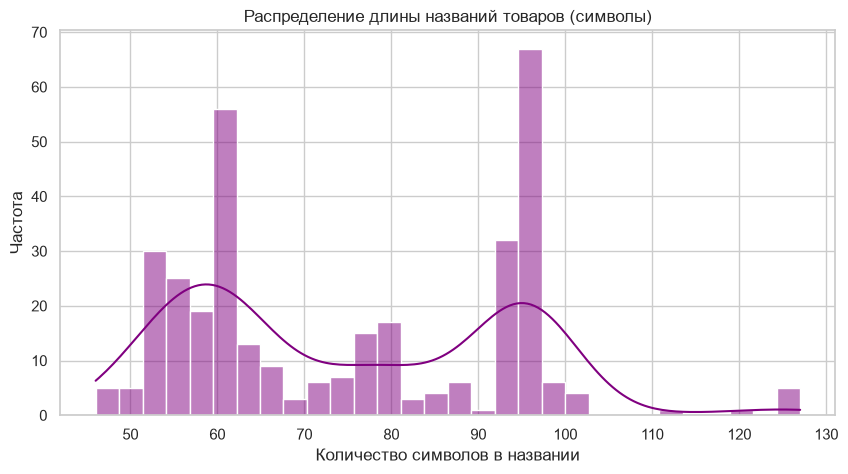

Средняя длина названия: 75.1 символов


In [69]:
df_final['name_length'] = df_final['name'].str.len()

plt.figure(figsize=(10, 5))
sns.histplot(df_final['name_length'], bins=30, kde=True, color='purple')
plt.title('Распределение длины названий товаров (символы)')
plt.xlabel('Количество символов в названии')
plt.ylabel('Частота')
plt.show()

print(f"Средняя длина названия: {df_final['name_length'].mean():.1f} символов")

In [80]:
#ВЫВОД ПО ГРАФИКУ 3 (средняя длина названия: {df_final['name_length'].mean():.1f} символов):
#Средняя длина названия — 75 символов. Это близко к идеалу для Ozon (рекомендуется 60-100).
#В названиях используются ключевые слова: размеры (190х210), тип ручек (крученые), плотность (крафт).
#Магазин хорошо оптимизирует карточки под поиск, не делая при этом 'переспам'.

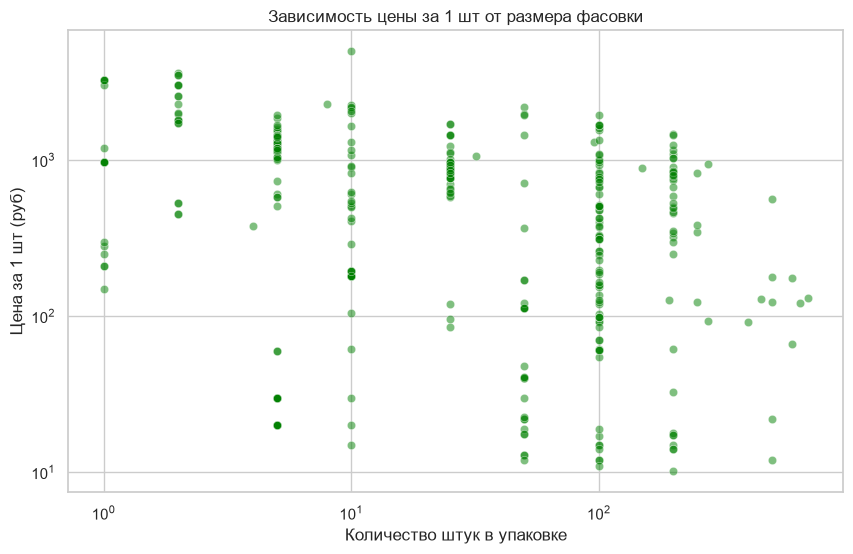

In [68]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='qty_in_pack', y='price_per_item', data=df_final, alpha=0.5, color='green')
plt.title('Зависимость цены за 1 шт от размера фасовки')
plt.xlabel('Количество штук в упаковке')
plt.ylabel('Цена за 1 шт (руб)')
plt.xscale('log')
plt.yscale('log')
plt.show()

In [ ]:
#ВЫВОД ПО ГРАФИКУ 4:
#Наблюдается ожидаемая картина: чем больше фасовка, тем ниже цена за 1 штуку (оптовая скидка).
#Однако есть исключения: пакеты премиум-класса по 100 шт. могут стоить дороже обычных,
#поэтому точка 100 шт. имеет большой разброс.

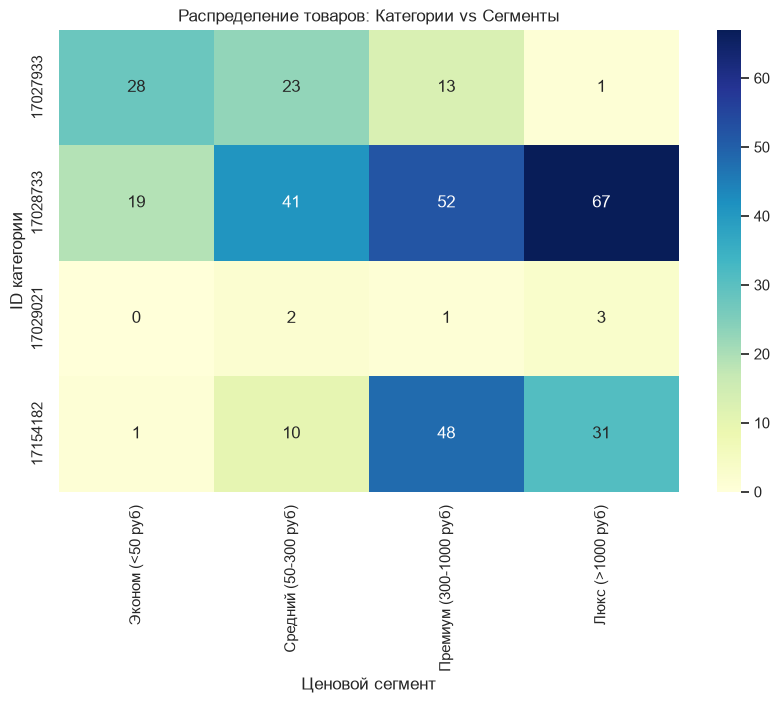

In [64]:
cross_tab = pd.crosstab(df_final['description_category_id'], df_final['segment'])
plt.figure(figsize=(10, 6))
sns.heatmap(cross_tab, annot=True, fmt='d', cmap='YlGnBu')
plt.title('Распределение товаров: Категории vs Сегменты')
plt.xlabel('Ценовой сегмент')
plt.ylabel('ID категории')
plt.show()

In [ ]:
# ВЫВОД ПО ГРАФИКУ 5:
#Категория 17028733 (крафт-пакеты) — абсолютный лидер. В ней представлены все сегменты,
#но особенно выделяется 'Люкс' (>1000 руб.) и 'Премиум'. Это флагманский товар магазина.
#Категория 17154182 в основном сосредоточена в среднем сегменте.
#Категория 17027933 (дой-паки) — это эконом-сегмент для фасовки.

In [66]:
pivot_qty = df_final.groupby('qty_in_pack').agg(
    count=('id', 'count'),
    avg_pack_price=('price', 'mean'),
    avg_item_price=('price_per_item', 'mean')
).sort_values('count', ascending=False).head(10)

print("СТАТИСТИКА ПО ПОПУЛЯРНЫМ ФАСОВКАМ:")
print(pivot_qty.to_string())

СТАТИСТИКА ПО ПОПУЛЯРНЫМ ФАСОВКАМ:
             count  avg_pack_price  avg_item_price
qty_in_pack                                       
100             78    46564.743590      465.647436
5               57     4699.245614      939.849123
25              42    22091.309524      883.652381
10              39     7794.230769      779.423077
200             36   113788.083333      568.940417
50              28    17694.107143      353.882143
2               20     4194.500000     2097.250000
1               17     1385.529412     1385.529412
500              5    89814.200000      179.628400
250              4   104903.000000      419.612000


In [82]:
# 1. Считаем кросс-таблицу (абсолютные значения)
cross_tab_clean = pd.crosstab(df_final_clean['description_category_id'], df_final_clean['segment'])

# 2. Переводим в проценты (доля каждого сегмента ВНУТРИ категории)
cross_tab_pct = pd.crosstab(df_final_clean['description_category_id'], df_final_clean['segment'], normalize='index') * 100

print("=== ДОЛЯ СЕГМЕНТОВ ВНУТРИ КАЖДОЙ КАТЕГОРИИ (%) ===")
print(cross_tab_pct.round(1).to_string())

=== ДОЛЯ СЕГМЕНТОВ ВНУТРИ КАЖДОЙ КАТЕГОРИИ (%) ===
segment                  Эконом (<50 руб)  Средний (50-300 руб)  Премиум (300-1000 руб)  Люкс (>1000 руб)
description_category_id                                                                                  
17027933                             43.1                  35.4                    20.0               1.5
17028733                             10.6                  22.9                    29.1              37.4
17029021                              0.0                  33.3                    16.7              50.0


In [83]:
#Анализ распределения ценовых сегментов внутри каждой категории выявил четкую специализацию:

#Категория 17028733 (Крафт-пакеты) - абсолютный флагман и локомотив прибыли.
#В ней сосредоточено 179 карточек (более 70% всей выборки). Главная особенность: 66.5% ассортимента этой категории - это Премиум и Люкс (29.1% и 37.4% соответственно). Магазин использует эту категорию для продажи дорогой, плотной упаковки с кручеными ручками (Toptwist), ориентированной на бизнес.

#Категория 17027933 — это зона Эконом-сегмента.
#Из 65 товаров 43.1% стоят до 50 рублей, еще 35.4% - в среднем сегменте. Это фасовочные пакеты и дой-паки для масс-маркета. Премиум и Люкс здесь практически отсутствуют (всего 1.5%).

#Категория 17029021 - нишевая (6 карточек).
#Половина товаров (50%) относится к сегменту Люкс. Скорее всего, это специфические подарочные позиции.

#Бизнес-инсайт: Магазин грамотно диверсифицирует матрицу. Он не пытается продавать всё подряд в одной категории, а использует 17028733 для высокомаржинальных B2B-продаж, а 17027933 — для обеспечения базового трафика и продаж расходников.

